# House Price Prediction

machine learning project using Python and scikit-learn.

The goal is to build a model that predicts house sale prices
based on property features.

In [2]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Everything is working!")

Pandas version: 3.1.0
NumPy version: 2.5.4
Everything is working!


In [3]:
df = pd.read_csv("../data/train.csv")

print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [7]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [8]:
print("Average price:", df["SalePrice"].mean())
print("Median price:", df["SalePrice"].median())
print("Minimum price:", df["SalePrice"].min())
print("Maximum price:", df["SalePrice"].max())

Average price: 180921.19589041095
Median price: 163000.0
Minimum price: 34900
Maximum price: 755000


In [9]:
df[["GrLivArea", "BedroomAbvGr", "FullBath", "OverallQual", "SalePrice"]].head(10)

,GrLivArea,BedroomAbvGr,FullBath,OverallQual,SalePrice
0,1710,3,2,7,208500
1,1262,3,2,6,181500
2,1786,3,2,7,223500
3,1717,3,1,7,140000
4,2198,4,2,8,250000
5,1362,1,1,5,143000
6,1694,3,2,8,307000
7,2090,3,2,7,200000
8,1774,2,2,7,129900
9,1077,2,1,5,118000


In [6]:
import matplotlib.pyplot as plt

In [8]:
import pandas as pd

df = pd.read_csv("../data/train.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(1460, 81)


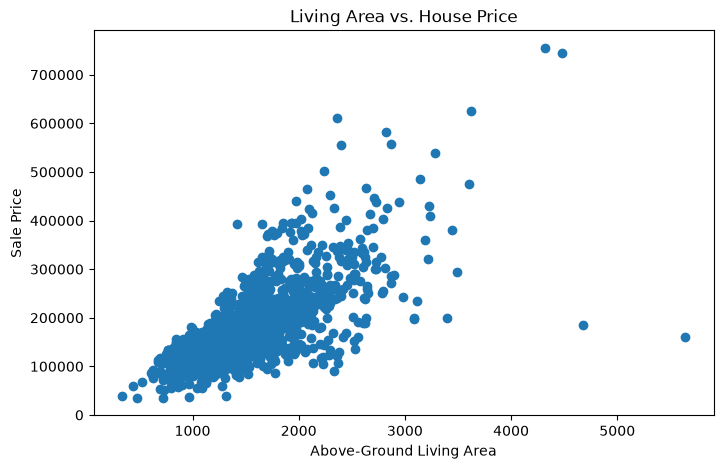

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df["GrLivArea"], df["SalePrice"])

plt.xlabel("Above-Ground Living Area")
plt.ylabel("Sale Price")
plt.title("Living Area vs. House Price")

plt.show()

In [ ]:
correlation = df["GrLivArea"].corr(df["SalePrice"])

print("Correlation:", correlation)

Correlation: 0.708624477612652


In [11]:
df["SalePrice"]

0       208500
1       181500
2       223500
3       140000
4       250000
         ...  
1455    175000
1456    210000
1457    266500
1458    142125
1459    147500
Name: SalePrice, Length: 1460, dtype: int64

In [12]:
type(df["SalePrice"])

pandas.Series

In [13]:
df[["GrLivArea", "BedroomAbvGr", "FullBath", "SalePrice"]].head()

,GrLivArea,BedroomAbvGr,FullBath,SalePrice
0,1710,3,2,208500
1,1262,3,2,181500
2,1786,3,2,223500
3,1717,3,1,140000
4,2198,4,2,250000


In [14]:
df[["OverallQual","GrLivArea","SalePrice"]].head(10)

,OverallQual,GrLivArea,SalePrice
0,7,1710,208500
1,6,1262,181500
2,7,1786,223500
3,7,1717,140000
4,8,2198,250000
5,5,1362,143000
6,8,1694,307000
7,7,2090,200000
8,7,1774,129900
9,5,1077,118000


In [15]:
large_houses = df[df["GrLivArea"] > 2000]

large_houses.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
11,12,60,RL,85.0,11924,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,New,Partial,345000
20,21,60,RL,101.0,14215,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,11,2006,New,Partial,325300
35,36,60,RL,108.0,13418,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2006,WD,Normal,309000


In [16]:
df["GrLivArea"] > 2000

0       False
1       False
2       False
3       False
4        True
        ...  
1455    False
1456     True
1457     True
1458    False
1459    False
Name: GrLivArea, Length: 1460, dtype: bool

In [17]:
print("Number of large houses:", len(large_houses))

Number of large houses: 214


In [18]:
large_houses["SalePrice"].mean()

np.float64(281696.2429906542)

In [19]:
df["SalePrice"].mean()

np.float64(180921.19589041095)

In [20]:
filtered_houses = df[
    (df["GrLivArea"] > 2000) &
    (df["SalePrice"] > 250000)
]

filtered_houses.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
11,12,60,RL,85.0,11924,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,New,Partial,345000
20,21,60,RL,101.0,14215,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,11,2006,New,Partial,325300
35,36,60,RL,108.0,13418,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2006,WD,Normal,309000
58,59,60,RL,66.0,13682,Pave,NaN,IR2,HLS,AllPub,...,0,NaN,NaN,NaN,0,10,2006,New,Partial,438780
65,66,60,RL,76.0,9591,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,10,2007,WD,Normal,317000


In [29]:
high_quality_houses = df[
    (df["OverallQual"] >= 8) &
    (df["SalePrice"] < 300000)
]

print(len(high_quality_houses))

127


In [30]:
df.sort_values("SalePrice")

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
495,496,30,C (all),60.0,7879,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdWo,NaN,0,11,2009,WD,Abnorml,34900
916,917,20,C (all),50.0,9000,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,10,2006,WD,Abnorml,35311
968,969,50,RM,50.0,5925,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdWo,NaN,0,5,2009,WD,Abnorml,37900
533,534,20,RL,50.0,5000,Pave,NaN,Reg,Low,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,39300
30,31,70,C (all),50.0,8500,Pave,Pave,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2008,WD,Normal,40000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
803,804,60,RL,107.0,13891,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2009,New,Partial,582933
898,899,20,RL,100.0,12919,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2010,New,Partial,611657
1169,1170,60,RL,118.0,35760,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,625000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000


In [31]:
df.sort_values(
    "SalePrice",
    ascending=False
).head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000
1169,1170,60,RL,118.0,35760,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,625000
898,899,20,RL,100.0,12919,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2010,New,Partial,611657
803,804,60,RL,107.0,13891,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2009,New,Partial,582933
1046,1047,60,RL,85.0,16056,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,New,Partial,556581
440,441,20,RL,105.0,15431,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2009,WD,Normal,555000
769,770,60,RL,47.0,53504,Pave,NaN,IR2,HLS,AllPub,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,538000
178,179,20,RL,63.0,17423,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,New,Partial,501837
798,799,60,RL,104.0,13518,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,New,Partial,485000


In [32]:
df.sort_values(
    "SalePrice",
    ascending=False
)[
    ["GrLivArea", "OverallQual", "BedroomAbvGr", "FullBath", "SalePrice"]
].head(10)

,GrLivArea,OverallQual,BedroomAbvGr,FullBath,SalePrice
691,4316,10,4,3,755000
1182,4476,10,4,3,745000
1169,3627,10,4,3,625000
898,2364,9,2,2,611657
803,2822,9,4,3,582933
1046,2868,9,4,3,556581
440,2402,10,2,2,555000
769,3279,8,4,3,538000
178,2234,9,1,2,501837
798,3140,9,4,3,485000


In [35]:
df.sort_values("SalePrice")[
    ["GrLivArea", "OverallQual", "SalePrice"]
].head(5)

,GrLivArea,OverallQual,SalePrice
495,720,4,34900
916,480,2,35311
968,968,3,37900
533,334,1,39300
30,1317,4,40000


In [36]:
print("Mean:", df["SalePrice"].mean())
print("Median:", df["SalePrice"].median())

Mean: 180921.19589041095
Median: 163000.0


In [37]:
df["SalePrice"].std()

np.float64(79442.50288288662)

In [39]:
import pandas as pd
import numpy as np

prices = np.array([150000, 200000, 250000, 300000, 350000])

print(prices)
print("Mean:", np.mean(prices))
print("Median:", np.median(prices))
print("Minimum:", np.min(prices))
print("Maximum:", np.max(prices))

[150000 200000 250000 300000 350000]
Mean: 250000.0
Median: 250000.0
Minimum: 150000
Maximum: 350000


In [40]:
prices_increased = prices * 1.10

print(prices_increased)

[165000. 220000. 275000. 330000. 385000.]


In [41]:
df[["GrLivArea", "OverallQual", "BedroomAbvGr", "SalePrice"]].describe()

,GrLivArea,OverallQual,BedroomAbvGr,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000
mean,1515.463699,6.099315,2.866438,180921.195890
std,525.480383,1.382997,0.815778,79442.502883
min,334.000000,1.000000,0.000000,34900.000000
25%,1129.500000,5.000000,2.000000,129975.000000
50%,1464.000000,6.000000,3.000000,163000.000000
75%,1776.750000,7.000000,3.000000,214000.000000
max,5642.000000,10.000000,8.000000,755000.000000


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("../data/train.csv")


In [4]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [5]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values.sort_values(ascending=False))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("../data/train.csv")


In [3]:
missing_percentage = df.isnull().mean() * 100

missing_percentage = missing_percentage[
    missing_percentage > 0
]

print(missing_percentage.sort_values(ascending=False))

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtExposure     2.602740
BsmtFinType2     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64


In [4]:
correlations = df[
    ["GrLivArea", "OverallQual", "BedroomAbvGr", "FullBath", "SalePrice"]
].corr()

print(correlations["SalePrice"].sort_values(ascending=False))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
FullBath        0.560664
BedroomAbvGr    0.168213
Name: SalePrice, dtype: float64


In [5]:
print("Mean sale price:", df["SalePrice"].mean())
print("Median sale price:", df["SalePrice"].median())
print("Minimum sale price:", df["SalePrice"].min())
print("Maximum sale price:", df["SalePrice"].max())

high_quality_houses = df[
    (df["OverallQual"] >= 8) &
    (df["SalePrice"] < 300000)
]

print("High-quality houses under $300,000:", len(high_quality_houses))

print("\nTop 5 columns with missing values:")
print(df.isnull().sum().sort_values(ascending=False).head(5))

Mean sale price: 180921.19589041095
Median sale price: 163000.0
Minimum sale price: 34900
Maximum sale price: 755000
High-quality houses under $300,000: 127

Top 5 columns with missing values:
PoolQC         1453
MiscFeature    1406
Alley          1369
Fence          1179
MasVnrType      872
dtype: int64


# House Price Dataset: Initial Analysis

## 1. Dataset Overview

The dataset contains 1,460 rows and 81 columns. Each row represents a house, and each column represents a feature describing the property or its sale price.

The dataset contains information such as living area, overall quality, number of bedrooms, number of bathrooms, and sale price.

## 2. Price Statistics

The target variable for this project is `SalePrice`, which represents the actual sale price of each house.

The following statistics help us understand the distribution of house prices:

- **Mean:** The average sale price of all houses.
- **Median:** The middle sale price when all prices are arranged in ascending order.
- **Minimum:** The lowest recorded sale price.
- **Maximum:** The highest recorded sale price.

These statistics help us understand the typical price range and variation in the dataset.

## 3. Living Area and Price

The scatter plot shows a positive relationship between `GrLivArea` and `SalePrice`.

In general, houses with larger above-ground living areas tend to have higher sale prices. However, houses with similar living areas can have different prices because other factors also influence house prices.

Some unusual observations appear in the graph, including very large houses with relatively low sale prices. These observations may be outliers and should be investigated before deciding how to handle them.

The correlation between living area and sale price is approximately **0.7**, indicating a fairly strong positive linear relationship.

Therefore, `GrLivArea` appears to be a useful feature for predicting house prices.

## 4. High-Quality Houses

High-quality houses are identified using the following conditions:

- `OverallQual` is greater than or equal to 8.
- `SalePrice` is less than $300,000.

These conditions allow us to investigate houses with high overall quality ratings that sold for less than $300,000.

The number of houses satisfying both conditions can be calculated using Pandas.

## 5. Missing Values

Missing values are entries where information is unavailable in the dataset.

Identifying missing values is important because some machine learning algorithms cannot work directly with missing data.

The missing-value analysis helps identify which columns require further investigation and possible preprocessing.

Missing values should not automatically be removed because they may contain useful information or have a specific meaning.

## 6. Feature Correlations

Correlation measures the strength and direction of the linear relationship between two numerical variables.

The initial analysis indicates a positive correlation of approximately 0.7 between `GrLivArea` and `SalePrice`.

Other features, including `OverallQual`, `BedroomAbvGr`, and `FullBath`, may also help predict sale prices.

Their correlations should be calculated and compared to determine which features have stronger linear relationships with the target variable.

However, correlation alone does not establish causation or guarantee better predictive performance.

## 7. Initial Conclusions

The initial analysis reveals that the dataset contains information that can be used to predict house prices.

The main findings are:

1. The dataset contains 1,460 houses and 81 columns.
2. Living area has a fairly strong positive linear relationship with sale price.
3. House prices vary even among properties with similar living areas.
4. Other features, such as overall quality, may provide additional predictive information.
5. Some observations appear unusual and may require further investigation.
6. Missing values must be examined and handled appropriately before model training.

The next step is to explore the dataset more deeply, investigate missing values and unusual observations, and prepare the features for machine learning.

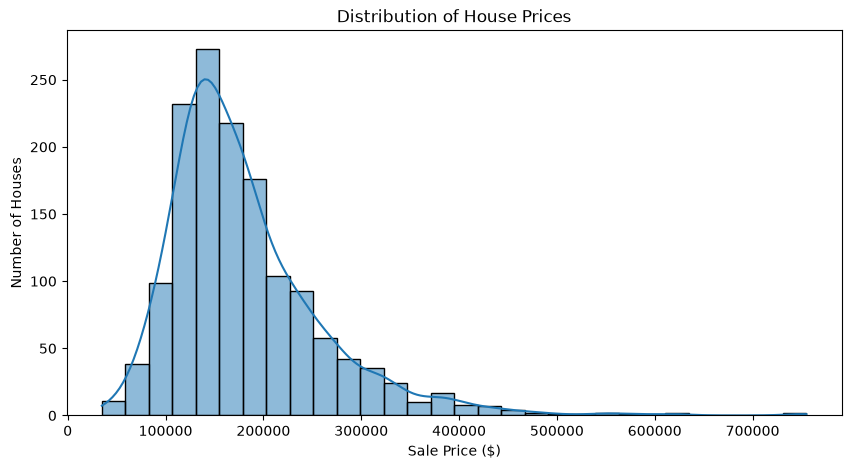

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("../data/train.csv")




plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="SalePrice", bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.show()

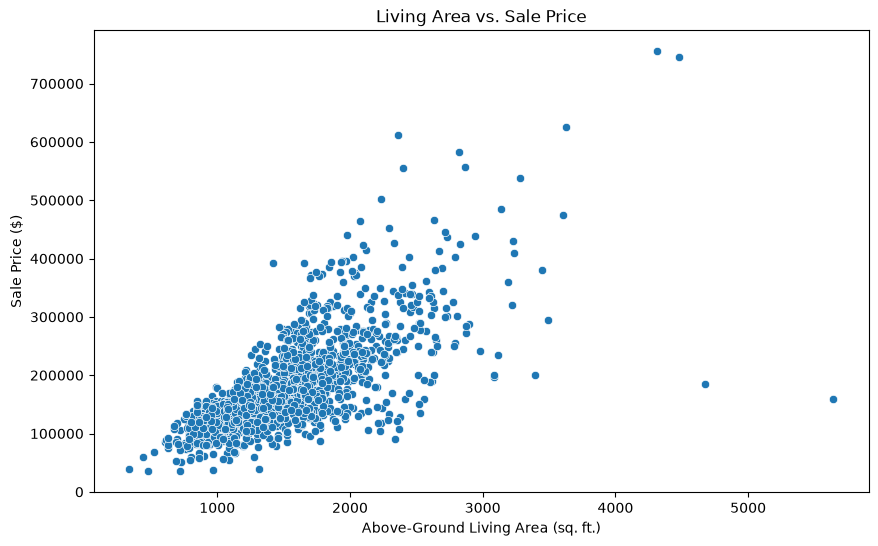

In [2]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs. Sale Price")
plt.xlabel("Above-Ground Living Area (sq. ft.)")
plt.ylabel("Sale Price ($)")

plt.show()

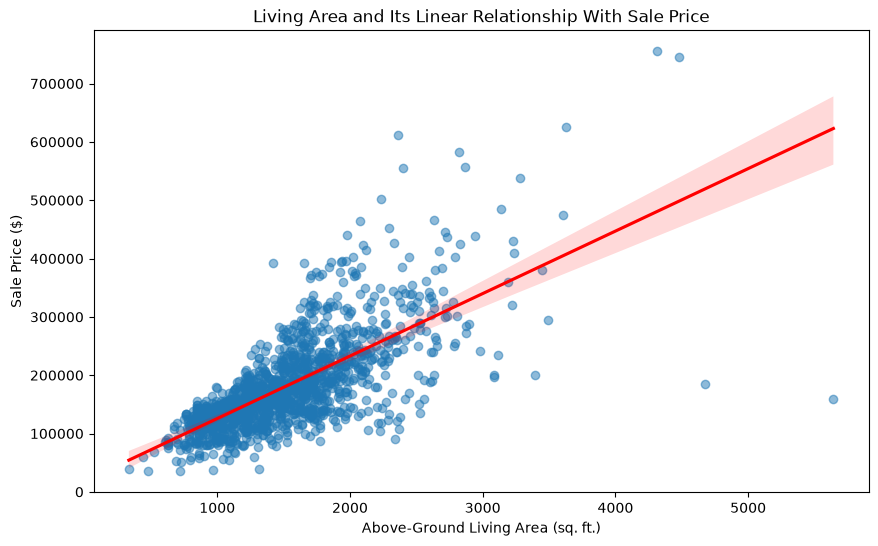

In [3]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Living Area and Its Linear Relationship With Sale Price")
plt.xlabel("Above-Ground Living Area (sq. ft.)")
plt.ylabel("Sale Price ($)")

plt.show()

In [4]:
quality_prices = df.groupby("OverallQual")["SalePrice"].mean()

print(quality_prices)

OverallQual
1      50150.000000
2      51770.333333
3      87473.750000
4     108420.655172
5     133523.347607
6     161603.034759
7     207716.423197
8     274735.535714
9     367513.023256
10    438588.388889
Name: SalePrice, dtype: float64


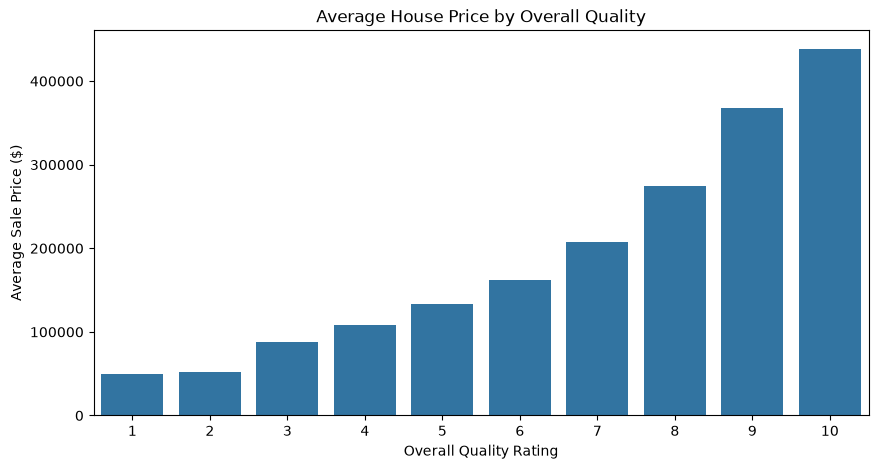

In [5]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="OverallQual",
    y="SalePrice",
    errorbar=None
)

plt.title("Average House Price by Overall Quality")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Average Sale Price ($)")

plt.show()

In [6]:
large_houses = df[df["GrLivArea"] > 4000]

large_houses[
    ["GrLivArea", "OverallQual", "BedroomAbvGr", "SalePrice"]
]

,GrLivArea,OverallQual,BedroomAbvGr,SalePrice
523,4676,10,3,184750
691,4316,10,4,755000
1182,4476,10,4,745000
1298,5642,10,3,160000


In [7]:
df.sort_values(
    ["GrLivArea", "SalePrice"],
    ascending=[False, True]
)[
    ["GrLivArea", "OverallQual", "BedroomAbvGr", "SalePrice"]
].head(10)

,GrLivArea,OverallQual,BedroomAbvGr,SalePrice
1298,5642,10,3,160000
523,4676,10,3,184750
1182,4476,10,4,745000
691,4316,10,4,755000
1169,3627,10,4,625000
185,3608,10,4,475000
304,3493,7,3,295000
1268,3447,8,4,381000
635,3395,6,8,200000
769,3279,8,4,538000


In [8]:
selected_features = [
    "GrLivArea",
    "OverallQual",
    "BedroomAbvGr",
    "FullBath",
    "GarageCars",
    "TotalBsmtSF",
    "SalePrice"
]

correlation_matrix = df[selected_features].corr()

correlation_matrix

,GrLivArea,OverallQual,BedroomAbvGr,FullBath,GarageCars,TotalBsmtSF,SalePrice
GrLivArea,1.000000,0.593007,0.521270,0.630012,0.467247,0.454868,0.708624
OverallQual,0.593007,1.000000,0.101676,0.550600,0.600671,0.537808,0.790982
BedroomAbvGr,0.521270,0.101676,1.000000,0.363252,0.086106,0.050450,0.168213
FullBath,0.630012,0.550600,0.363252,1.000000,0.469672,0.323722,0.560664
GarageCars,0.467247,0.600671,0.086106,0.469672,1.000000,0.434585,0.640409
TotalBsmtSF,0.454868,0.537808,0.050450,0.323722,0.434585,1.000000,0.613581
SalePrice,0.708624,0.790982,0.168213,0.560664,0.640409,0.613581,1.000000


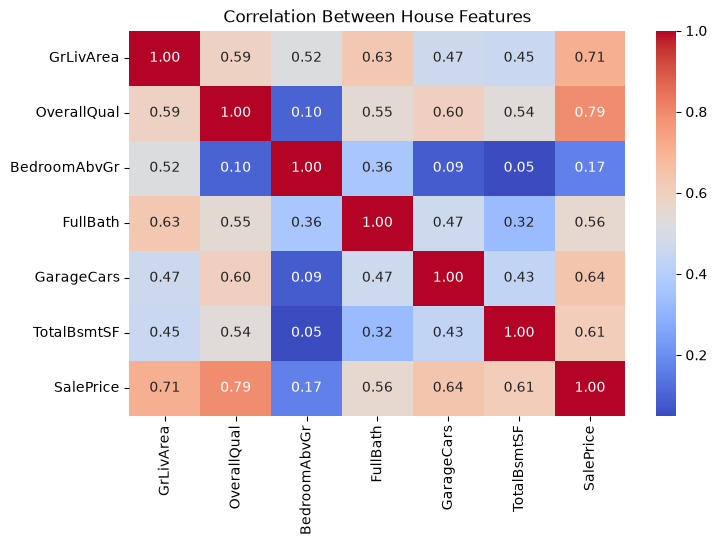

In [11]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between House Features")

plt.show()